# 📊 Complete Matplotlib Data Visualization Guide
**Flow of this notebook:** Create data (NumPy) → Convert to DataFrame (Pandas) → Visualize (Matplotlib)

| # | Plot type | Variations |
|---|-----------|-----------|
| 1 | Line plot | 25 |
| 2 | Bar plot | 26 |
| 3 | Scatter plot | 25 |
| 4 | Histogram | 25 |
| 5 | Pie / Donut chart | 25 |
| 6 | Box & Violin plot | 24 |
| 7 | Area / Stack plot | 25 |
| 8 | Heatmap / Image / Contour | 27 |
| 9 | Other plots (3D, Polar, Stem, Step, Errorbar, Quiver ...) | 31 |
| 10 | Layouts, styles & dashboards | 9 |

Every cell is **independent**: it only needs the setup cells (Steps 1-4). Run those first, then run any plot cell you like.

## STEP 1 — Import libraries

In [1]:
# numpy  -> create numbers / arrays
# pandas -> hold the data in tables (DataFrames)
# matplotlib.pyplot -> draw the charts
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates      # helps format date axes
import warnings
warnings.filterwarnings('ignore')      # keep the notebook output clean

%matplotlib inline

# Global look & feel for every plot (can be changed any time)
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.grid': False,
})

# Newer matplotlib uses orientation='horizontal', older uses vert=False (box/violin/stem)
HORIZ = {'orientation': 'horizontal'} if tuple(map(int, matplotlib.__version__.split('.')[:2])) >= (3, 10) else {'vert': False}
print('Matplotlib version:', matplotlib.__version__)

Matplotlib version: 3.9.4


## STEP 2 — Create the datasets (NumPy)
We create 3 small, realistic datasets so every plot type has suitable data.

In [2]:
np.random.seed(42)   # same random numbers every run -> reproducible results

# ---------- Dataset 1: TIME SERIES (24 months of a business) ----------
dates    = pd.date_range('2023-01-01', periods=24, freq='MS')   # first day of 24 months
trend    = 200 + np.arange(24) * 5                               # steady growth
season   = 30 * np.sin(np.arange(24) / 12 * 2 * np.pi)           # yearly up/down wave
sales    = trend + season + np.random.normal(0, 15, 24)          # + random noise
expenses = sales * 0.6 + np.random.normal(0, 8, 24)
visitors = sales * 12 + np.random.normal(0, 200, 24)
sales_b  = sales * 0.7 + np.random.normal(0, 10, 24)             # a second product

# ---------- Dataset 2: CATEGORY SUMMARY (5 product categories) ----------
categories = ['Electronics', 'Clothing', 'Grocery', 'Toys', 'Books']
sales_cat  = [450, 320, 500, 150, 210]
profit_cat = [90, 60, 75, -20, 45]
returns    = [30, 45, 10, 12, 8]
rating     = [4.3, 3.9, 4.5, 4.0, 4.7]
q1, q2, q3, q4 = [100, 70, 120, 30, 50], [110, 80, 125, 35, 52], [115, 82, 130, 40, 53], [125, 88, 125, 45, 55]

# ---------- Dataset 3: PEOPLE / EMPLOYEES (300 rows) ----------
n          = 300
age        = np.random.randint(21, 60, n)
experience = np.clip(age - 21 - np.random.randint(0, 6, n), 0, None)
salary     = 30000 + experience * 2500 + np.random.normal(0, 8000, n)
height     = np.random.normal(170, 10, n)
weight     = 0.9 * (height - 100) + np.random.normal(0, 8, n)
score      = np.clip(np.random.normal(70, 12, n), 0, 100)
gender     = np.random.choice(['Male', 'Female'], n)
department = np.random.choice(['IT', 'HR', 'Sales', 'Finance'], n, p=[0.4, 0.15, 0.3, 0.15])
print('Raw data created ✔')

Raw data created ✔


## STEP 3 — Convert the data into Pandas DataFrames

In [3]:
# A DataFrame is a table: rows = records, columns = variables
df_time = pd.DataFrame({'Date': dates, 'Sales': sales.round(1), 'Expenses': expenses.round(1),
                        'Visitors': visitors.astype(int), 'Sales_B': sales_b.round(1)})

df_time['Profit'] = df_time['Sales'] - df_time['Expenses']      # new calculated column


df_cat = pd.DataFrame({'Category': categories, 'Sales': sales_cat, 'Profit': profit_cat,
                       'Returns': returns, 'Rating': rating, 'Q1': q1, 'Q2': q2, 'Q3': q3, 'Q4': q4,
                       'Error': [20, 15, 25, 10, 12], 'Sales_2022': [400, 300, 470, 170, 190]})

df_people = pd.DataFrame({'Age': age, 'Experience': experience, 'Salary': salary.round(0),
                          'Height': height.round(1), 'Weight': weight.round(1), 'Score': score.round(1),
                          'Gender': gender, 'Department': department})

# A 7x24 table (weekday x hour) used for heatmaps, and a correlation matrix
df_heat = pd.DataFrame(np.random.randint(0, 100, (7, 24)),
                       index=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], columns=range(24))
corr = df_people.select_dtypes('number').corr()                  # correlation between numeric columns

# Short aliases so plotting code stays small and readable
t, c, p = df_time, df_cat, df_people
display(t.head(3)); display(c); display(p.head(3))

,Date,Sales,Expenses,Visitors,Sales_B,Profit
0,2023-01-01,207.5,120.1,2558,144.9,87.4
1,2023-02-01,217.9,131.6,2262,168.2,86.3
2,2023-03-01,245.7,138.2,3013,145.8,107.5


,Category,Sales,Profit,Returns,Rating,Q1,Q2,Q3,Q4,Error,Sales_2022
0,Electronics,450,90,30,4.3,100,110,115,125,20,400
1,Clothing,320,60,45,3.9,70,80,82,88,15,300
2,Grocery,500,75,10,4.5,120,125,130,125,25,470
3,Toys,150,-20,12,4.0,30,35,40,45,10,170
4,Books,210,45,8,4.7,50,52,53,55,12,190


,Age,Experience,Salary,Height,Weight,Score,Gender,Department
0,33,8,48443.0,165.8,66.8,69.1,Male,HR
1,23,0,41357.0,163.5,80.8,52.2,Female,IT
2,59,38,128686.0,179.1,67.9,77.8,Female,Sales


## STEP 4 — Quick look at the data (always do this before plotting)

In [ ]:
print(p.info())               # column names, data types, missing values
display(p.describe())         # count, mean, std, min, quartiles, max

---
# 1. LINE PLOT
Best for trends over time. Main function: `ax.plot(x, y)`.

**Variations in this section: 25**

### 1.1  Basic line plot

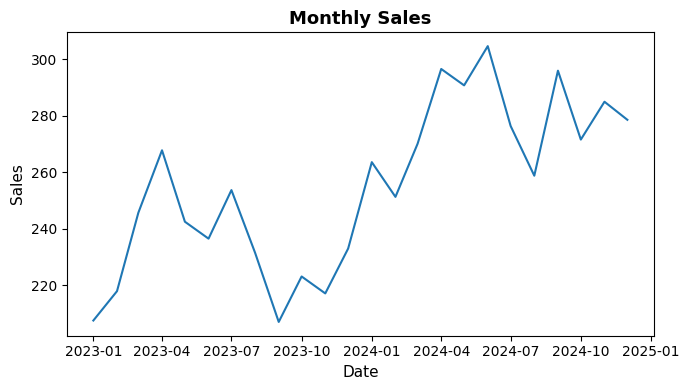

In [6]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# plot(x, y) connects the points with a straight line
ax.plot(t['Date'], t['Sales'])
ax.set_title('Monthly Sales'); ax.set_xlabel('Date'); ax.set_ylabel('Sales')

# Step 3: show it
plt.tight_layout()
plt.show()

In [7]:
t

,Date,Sales,Expenses,Visitors,Sales_B,Profit
0,2023-01-01,207.5,120.1,2558,144.9,87.4
1,2023-02-01,217.9,131.6,2262,168.2,86.3
2,2023-03-01,245.7,138.2,3013,145.8,107.5
3,2023-04-01,267.8,163.7,3137,195.7,104.1
4,2023-05-01,242.5,140.7,2774,170.6,101.8
5,2023-06-01,236.5,139.6,2960,162.6,96.9
6,2023-07-01,253.7,147.4,3250,178.5,106.3
7,2023-08-01,231.5,153.7,2964,142.2,77.8
8,2023-09-01,207.0,124.1,2315,142.7,82.9
9,2023-10-01,223.1,125.4,2615,159.8,97.7


### 1.2  Line with markers

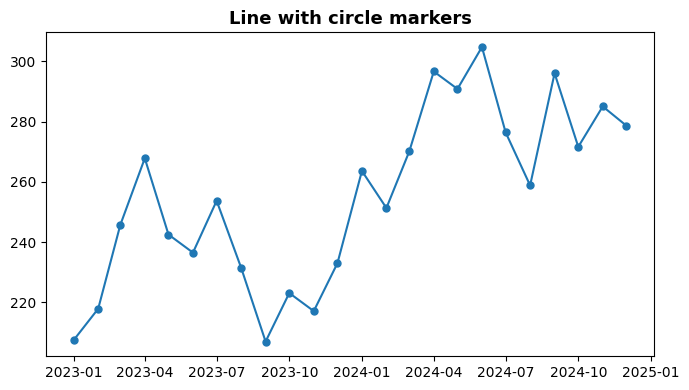

In [10]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# marker draws a symbol on every data point ('o' circle, 's' square, '^' triangle ...)
ax.plot(t['Date'], t['Sales'], marker='o', markersize=5)
ax.set_title('Line with circle markers')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.3  Line styles (solid, dashed, dash-dot, dotted)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# linestyle controls the pattern of the line
for i, ls in enumerate(['-', '--', '-.', ':']):
    ax.plot(t['Date'], t['Sales'] + i * 60, linestyle=ls, label=f"linestyle '{ls}'")
ax.legend(); ax.set_title('Line styles')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.4  Color, width and transparency

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# color = name/hex, linewidth = thickness, alpha = transparency (0..1)
ax.plot(t['Date'], t['Sales'], color='crimson', linewidth=3, alpha=0.8)
ax.set_title('Custom color / width / alpha')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.5  Multiple lines with legend

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# every plot() call adds a line; label= is shown by legend()
ax.plot(t['Date'], t['Sales'], label='Sales')
ax.plot(t['Date'], t['Expenses'], label='Expenses')
ax.plot(t['Date'], t['Profit'], label='Profit')
ax.legend(loc='upper left'); ax.set_title('Sales vs Expenses vs Profit')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.6  Grid lines

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# grid() makes values easier to read
ax.plot(t['Date'], t['Sales'], color='green')
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title('Line plot with grid')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.7  Annotate the peak value

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# idxmax() gives the row number of the biggest value
i = t['Sales'].idxmax()
ax.plot(t['Date'], t['Sales'])
ax.annotate('Peak', xy=(t['Date'][i], t['Sales'][i]), xytext=(-60, 15), textcoords='offset points',
            arrowprops=dict(arrowstyle='->', color='red'), color='red')
ax.set_title('Annotated maximum')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.8  Fill under the line

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# fill_between colours the area between the line and a baseline
ax.plot(t['Date'], t['Sales'], color='navy')
ax.fill_between(t['Date'], t['Sales'], alpha=0.3, color='navy')
ax.set_title('Line + filled area')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.9  Two Y axes (twinx)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# twinx() creates a second y-axis sharing the same x-axis (different units!)
ax.plot(t['Date'], t['Sales'], color='tab:blue'); ax.set_ylabel('Sales', color='tab:blue')
ax2 = ax.twinx()
ax2.plot(t['Date'], t['Visitors'], color='tab:red'); ax2.set_ylabel('Visitors', color='tab:red')
ax.set_title('Sales and Visitors (dual axis)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.10  Rolling (moving) average

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# rolling(3).mean() smooths noise using the last 3 values
ax.plot(t['Date'], t['Sales'], alpha=0.4, label='Raw')
ax.plot(t['Date'], t['Sales'].rolling(3).mean(), linewidth=3, label='3-month average')
ax.legend(); ax.set_title('Smoothing with moving average')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.11  Logarithmic y-axis

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# log scale is useful when values grow multiplicatively
ax.plot(np.arange(1, 25), 2 ** np.arange(1, 25) / 100)
ax.set_yscale('log'); ax.grid(True, which='both', alpha=0.3)
ax.set_title('Exponential growth on a log scale')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.12  Format date axis

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# DateFormatter + MonthLocator control how dates appear
ax.plot(t['Date'], t['Sales'])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))     # tick every 3 months
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))     # e.g. Jan-23
fig.autofmt_xdate()                                             # rotate labels nicely
ax.set_title('Custom date format')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.13  Mark only some points (markevery)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# markevery=3 -> a marker on every 3rd point only
ax.plot(t['Date'], t['Sales'], marker='D', markevery=3, markersize=8, color='purple')
ax.set_title('markevery=3')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.14  Mean ± standard deviation band

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# rolling mean line with a shaded band showing the variation
m = t['Sales'].rolling(4).mean(); s = t['Sales'].rolling(4).std()
ax.plot(t['Date'], m, color='teal')
ax.fill_between(t['Date'], m - s, m + s, color='teal', alpha=0.25)
ax.set_title('Rolling mean ± 1 std')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.15  Horizontal / vertical reference lines

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# axhline/axvline draw a line across the whole axis
ax.plot(t['Date'], t['Sales'])
ax.axhline(t['Sales'].mean(), color='red', linestyle='--', label='Average')
ax.axvline(pd.Timestamp('2024-01-01'), color='gray', linestyle=':', label='New year 2024')
ax.legend(); ax.set_title('Reference lines')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.16  Highlight a time period (axvspan)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# axvspan shades a vertical band between two x positions
ax.plot(t['Date'], t['Sales'])
ax.axvspan(pd.Timestamp('2023-11-01'), pd.Timestamp('2024-01-01'), color='orange', alpha=0.3, label='Holiday season')
ax.legend(); ax.set_title('Highlighted period')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.17  Cumulative line

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# cumsum() adds values up month after month
ax.plot(t['Date'], t['Profit'].cumsum(), marker='o', color='darkgreen')
ax.set_title('Cumulative profit'); ax.set_ylabel('Total profit')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.18  Stacked line subplots (shared x-axis)

In [ ]:
# Step: build a custom figure layout, then draw
# 3 rows, 1 column, all share the same x-axis
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(7, 6))
for a, col, colr in zip(axes, ['Sales', 'Expenses', 'Profit'], ['blue', 'orange', 'green']):
    a.plot(t['Date'], t[col], color=colr); a.set_ylabel(col)
fig.suptitle('Shared x-axis subplots')
plt.tight_layout()
plt.show()

### 1.19  Text label on each point

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# ax.text(x, y, text) writes a label at a position
d = t.head(12)
ax.plot(d['Date'], d['Sales'], marker='o')
for x, y in zip(d['Date'], d['Sales']):
    ax.text(x, y + 4, f'{y:.0f}', ha='center', fontsize=8)
ax.set_title('Values written on the line')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.20  Custom dash pattern

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# dashes=(on, off, on, off ...) lengths in points
ax.plot(t['Date'], t['Sales'], dashes=(6, 2, 2, 2), linewidth=2, color='black')
ax.set_title('Custom dash pattern')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.21  Percentage change

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# pct_change() = (this month - last month) / last month
ax.plot(t['Date'], t['Sales'].pct_change() * 100, marker='o')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('% change'); ax.set_title('Month-over-month growth')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.22  Minimal style (hide spines)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# spines are the 4 border lines of the axes
ax.plot(t['Date'], t['Sales'], color='#444')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Clean minimal look')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.23  Mathematical curves (sin & cos)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# linspace creates 200 evenly spaced numbers between 0 and 2*pi
x = np.linspace(0, 2 * np.pi, 200)
ax.plot(x, np.sin(x), label='sin(x)'); ax.plot(x, np.cos(x), label='cos(x)')
ax.legend(); ax.axhline(0, color='gray', linewidth=0.5); ax.set_title('Sine and Cosine')

# Step 3: show it
plt.tight_layout()
plt.show()

### 1.24  Hand-drawn (xkcd) style

In [ ]:
# Step: build a custom figure layout, then draw
# xkcd() context makes the chart look hand drawn
with plt.xkcd():
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(t['Date'], t['Sales']); ax.set_title('xkcd style')
plt.tight_layout()
plt.show()

### 1.25  Pandas shortcut: DataFrame.plot()

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# pandas can plot directly; ax=ax puts it on our matplotlib axes
t.set_index('Date')[['Sales', 'Profit']].plot(ax=ax)
ax.set_title('df.plot() with matplotlib axes')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 2. BAR PLOT
Best for comparing categories. Main functions: `ax.bar()` (vertical) and `ax.barh()` (horizontal).

**Variations in this section: 26**

### 2.1  Basic vertical bar

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.bar(c['Category'], c['Sales'])
ax.set_title('Sales by category'); ax.set_ylabel('Sales')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.2  Different color for each bar

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# pass a list of colors (one per bar)
ax.bar(c['Category'], c['Sales'], color=['#e63946', '#f4a261', '#2a9d8f', '#457b9d', '#8d5fd3'])
ax.set_title('Colorful bars')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.3  Horizontal bar

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# barh = horizontal bars (great for long labels)
ax.barh(c['Category'], c['Sales'], color='teal')
ax.set_title('Horizontal bar'); ax.set_xlabel('Sales')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.4  Value labels on bars

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# bar_label writes the value on top of each bar
bars = ax.bar(c['Category'], c['Sales'], color='skyblue')
ax.bar_label(bars, padding=3)
ax.set_title('Bars with values')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.5  Grouped bars (2 series)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# shift the 2nd set of bars by one bar-width so they sit side by side
x = np.arange(len(c)); w = 0.35
ax.bar(x - w/2, c['Sales_2022'], w, label='2022')
ax.bar(x + w/2, c['Sales'], w, label='2023')
ax.set_xticks(x); ax.set_xticklabels(c['Category']); ax.legend(); ax.set_title('2022 vs 2023')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.6  Grouped bars (4 series - quarters)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
x = np.arange(len(c)); w = 0.2
for i, q in enumerate(['Q1', 'Q2', 'Q3', 'Q4']):
    ax.bar(x + (i - 1.5) * w, c[q], w, label=q)         # offset each quarter
ax.set_xticks(x); ax.set_xticklabels(c['Category']); ax.legend(ncol=4); ax.set_title('Quarterly sales')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.7  Stacked bars (2 series)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# bottom= tells where the 2nd bar starts (on top of the 1st)
ax.bar(c['Category'], c['Sales'] - c['Returns'], label='Kept')
ax.bar(c['Category'], c['Returns'], bottom=c['Sales'] - c['Returns'], label='Returned')
ax.legend(); ax.set_title('Stacked: kept vs returned')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.8  Stacked bars (4 quarters)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
bottom = np.zeros(len(c))                                # running total of height
for q in ['Q1', 'Q2', 'Q3', 'Q4']:
    ax.bar(c['Category'], c[q], bottom=bottom, label=q)
    bottom += c[q].values
ax.legend(); ax.set_title('Stacked quarters')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.9  100% stacked bars

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# divide each quarter by the row total to get percentages
qs = c[['Q1', 'Q2', 'Q3', 'Q4']]; pct = qs.div(qs.sum(axis=1), axis=0) * 100
bottom = np.zeros(len(c))
for q in pct.columns:
    ax.bar(c['Category'], pct[q], bottom=bottom, label=q); bottom += pct[q].values
ax.set_ylabel('%'); ax.legend(ncol=4, loc='lower center'); ax.set_title('100% stacked')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.10  Sorted bars (descending)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# sort_values puts the biggest bar first -> easier ranking
d = c.sort_values('Sales', ascending=False)
ax.bar(d['Category'], d['Sales'], color='slateblue')
ax.set_title('Ranked categories')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.11  Bars with error bars

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# yerr adds a +/- whisker to each bar; capsize sets whisker cap width
ax.bar(c['Category'], c['Sales'], yerr=c['Error'], capsize=6, color='lightgreen', edgecolor='black')
ax.set_title('Bars with error bars')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.12  Hatch patterns

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# hatch fills bars with patterns (useful for black & white print)
ax.bar(c['Category'], c['Sales'], color='white', edgecolor='black', hatch='//')
ax.set_title('Hatched bars')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.13  Edge color and line width

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.bar(c['Category'], c['Sales'], color='gold', edgecolor='darkred', linewidth=2)
ax.set_title('Bars with borders')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.14  Colormap based on value

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# map value -> color so taller bars look darker
norm = (c['Sales'] - c['Sales'].min()) / (c['Sales'].max() - c['Sales'].min())
ax.bar(c['Category'], c['Sales'], color=plt.cm.viridis(norm))
ax.set_title('Color by value (viridis)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.15  Positive / negative bars

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# green if profit >= 0 else red
cols = ['green' if v >= 0 else 'red' for v in c['Profit']]
ax.bar(c['Category'], c['Profit'], color=cols); ax.axhline(0, color='black')
ax.set_title('Profit and loss')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.16  Horizontal grouped bars

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
y = np.arange(len(c)); h = 0.35
ax.barh(y - h/2, c['Sales_2022'], h, label='2022'); ax.barh(y + h/2, c['Sales'], h, label='2023')
ax.set_yticks(y); ax.set_yticklabels(c['Category']); ax.legend(); ax.set_title('Horizontal grouped')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.17  Back-to-back (butterfly) bars

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# negative values go left, positive go right
ax.barh(c['Category'], -c['Returns'], color='tomato', label='Returns')
ax.barh(c['Category'], c['Profit'].clip(lower=0), color='seagreen', label='Profit')
ax.axvline(0, color='black'); ax.legend(); ax.set_title('Butterfly chart')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.18  Lollipop chart

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# a thin vertical line (vlines) + a dot = lighter alternative to bars
ax.vlines(c['Category'], 0, c['Sales'], color='gray')
ax.plot(c['Category'], c['Sales'], 'o', markersize=12, color='crimson')
ax.set_title('Lollipop chart')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.19  Bar + line combo

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# bars for Sales (left axis) and a line for Rating (right axis)
ax.bar(c['Category'], c['Sales'], color='lightsteelblue'); ax.set_ylabel('Sales')
ax2 = ax.twinx(); ax2.plot(c['Category'], c['Rating'], 'ro-'); ax2.set_ylabel('Rating'); ax2.set_ylim(3, 5)
ax.set_title('Sales (bar) and Rating (line)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.20  Highlight the maximum bar

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
cols = ['lightgray'] * len(c); cols[c['Sales'].idxmax()] = 'crimson'     # only the best one is colored
ax.bar(c['Category'], c['Sales'], color=cols)
ax.set_title('Focus on the top category')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.21  Rotated tick labels

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.bar(c['Category'], c['Sales'])
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')                  # rotate x labels 45 degrees
ax.set_title('Rotated labels')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.22  Bar with log scale

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.bar(c['Category'], c['Sales'], color='orchid'); ax.set_yscale('log')
ax.set_title('Log scale bars')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.23  Count plot using value_counts()

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# value_counts() counts how many rows each Department has
counts = p['Department'].value_counts()
ax.bar(counts.index, counts.values, color='steelblue'); ax.bar_label(ax.containers[0])
ax.set_title('Employees per department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.24  Average per group (groupby)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# groupby + mean = average salary of each department
g = p.groupby('Department')['Salary'].mean().sort_values()
ax.barh(g.index, g.values, color='coral'); ax.set_xlabel('Average salary')
ax.set_title('Mean salary by department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.25  Stacked horizontal bars (Gender x Department)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# crosstab counts combinations of two categories
ct = pd.crosstab(p['Department'], p['Gender'])
ax.barh(ct.index, ct['Female'], label='Female'); ax.barh(ct.index, ct['Male'], left=ct['Female'], label='Male')
ax.legend(); ax.set_title('Gender split per department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 2.26  Pandas shortcut: DataFrame.plot.bar()

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
c.set_index('Category')[['Q1', 'Q2', 'Q3', 'Q4']].plot.bar(ax=ax, rot=0)
ax.set_title('df.plot.bar()')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 3. SCATTER PLOT
Best for the relationship between two numeric variables. Main function: `ax.scatter(x, y)`.

**Variations in this section: 25**

### 3.1  Basic scatter

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.scatter(p['Height'], p['Weight'])
ax.set_xlabel('Height'); ax.set_ylabel('Weight'); ax.set_title('Height vs Weight')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.2  Color, size, transparency

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# s = marker size, alpha = transparency, c = color
ax.scatter(p['Height'], p['Weight'], s=60, alpha=0.5, c='green')
ax.set_title('Custom marker style')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.3  Color by category (loop)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# draw one group at a time so each gets its own color + legend entry
for g, d in p.groupby('Gender'):
    ax.scatter(d['Height'], d['Weight'], label=g, alpha=0.6)
ax.legend(); ax.set_title('Gender groups')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.4  Bubble chart (size = third variable)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# the size of each bubble shows Salary
ax.scatter(p['Experience'], p['Score'], s=p['Salary'] / 800, alpha=0.4, color='purple')
ax.set_xlabel('Experience'); ax.set_ylabel('Score'); ax.set_title('Bubble size = Salary')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.5  Color by value + colorbar

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# c= takes numbers, cmap converts them to colors, colorbar explains them
sc = ax.scatter(p['Experience'], p['Salary'], c=p['Age'], cmap='viridis')
plt.colorbar(sc, ax=ax, label='Age'); ax.set_title('Colored by Age')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.6  Marker styles

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# o circle, s square, ^ triangle, D diamond, * star, + plus, x cross
for i, m in enumerate(['o', 's', '^', 'D', '*', 'P', 'X']):
    ax.scatter(i, 1, marker=m, s=200)
ax.set_yticks([]); ax.set_title('Marker gallery')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.7  Regression (trend) line

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# polyfit(x, y, 1) finds slope & intercept of the best straight line
m, b = np.polyfit(p['Experience'], p['Salary'], 1)
ax.scatter(p['Experience'], p['Salary'], alpha=0.5)
ax.plot(p['Experience'], m * p['Experience'] + b, color='red')
ax.set_title(f'Salary = {m:.0f} x Experience + {b:.0f}')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.8  Annotate outliers

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# label the 3 highest salaries
ax.scatter(p['Experience'], p['Salary'], alpha=0.5)
for _, r in p.nlargest(3, 'Salary').iterrows():
    ax.annotate(f"{r['Salary']:.0f}", (r['Experience'], r['Salary']), xytext=(5, 5), textcoords='offset points', color='red')
ax.set_title('Top 3 salaries labelled')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.9  Edge colors

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.scatter(p['Height'], p['Weight'], s=70, facecolor='yellow', edgecolor='black', linewidth=1)
ax.set_title('Marker edges')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.10  Log-log scale

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.scatter(p['Salary'], p['Experience'] + 1, alpha=0.5)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title('Log-log scatter')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.11  Scatter with marginal histograms

In [ ]:
# Step: build a custom figure layout, then draw
# a grid where small histograms sit on top and right of the scatter
fig = plt.figure(figsize=(6, 6))
gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4), hspace=0.05, wspace=0.05)
ax = fig.add_subplot(gs[1, 0]); ax_x = fig.add_subplot(gs[0, 0], sharex=ax); ax_y = fig.add_subplot(gs[1, 1], sharey=ax)
ax.scatter(p['Height'], p['Weight'], alpha=0.5)
ax_x.hist(p['Height'], bins=20); ax_y.hist(p['Weight'], bins=20, orientation='horizontal')
ax_x.tick_params(labelbottom=False); ax_y.tick_params(labelleft=False)
plt.tight_layout()
plt.show()

### 3.12  Scatter matrix (pairplot)

In [ ]:
# Step: build a custom figure layout, then draw
# pandas draws every numeric column against every other one
pd.plotting.scatter_matrix(p[['Age', 'Experience', 'Salary', 'Score']], figsize=(8, 8), diagonal='hist', alpha=0.5)
plt.tight_layout()
plt.show()

### 3.13  Hexbin (for dense data)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# hexbin counts points inside hexagons -> avoids overplotting
hb = ax.hexbin(p['Height'], p['Weight'], gridsize=15, cmap='Blues')
plt.colorbar(hb, ax=ax, label='count'); ax.set_title('Hexbin density')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.14  2D histogram density

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
h = ax.hist2d(p['Height'], p['Weight'], bins=20, cmap='magma')
plt.colorbar(h[3], ax=ax, label='count'); ax.set_title('hist2d density')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.15  Jittered categorical scatter

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# add small random noise to x so points do not overlap
codes = p['Department'].astype('category').cat.codes
ax.scatter(codes + np.random.uniform(-0.2, 0.2, len(p)), p['Salary'], alpha=0.5)
ax.set_xticks(range(4)); ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('Salary by department (jitter)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.16  Multiple groups (Department)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
for dep, d in p.groupby('Department'):
    ax.scatter(d['Experience'], d['Salary'], label=dep, alpha=0.6, s=25)
ax.legend(title='Department'); ax.set_title('Salary vs Experience by department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.17  Quadrant lines (mean lines)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.scatter(p['Experience'], p['Score'], alpha=0.5)
ax.axvline(p['Experience'].mean(), color='red', linestyle='--'); ax.axhline(p['Score'].mean(), color='red', linestyle='--')
ax.set_title('4 quadrants around the mean')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.18  Size legend

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# legend_elements builds a legend explaining marker sizes
sc = ax.scatter(p['Age'], p['Score'], s=p['Experience'] * 4, alpha=0.4)
h, l = sc.legend_elements(prop='sizes', num=4, alpha=0.5)
ax.legend(h, l, title='Experience-size'); ax.set_title('Size legend')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.19  Scatter with error bars

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# errorbar with fmt='o' draws points + uncertainty lines
ax.errorbar(c['Sales_2022'], c['Sales'], xerr=15, yerr=c['Error'], fmt='o', capsize=4)
ax.set_xlabel('2022'); ax.set_ylabel('2023'); ax.set_title('Points with errors')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.20  Grid of scatter plots

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for a, (xcol, ycol) in zip(axes, [('Age', 'Salary'), ('Experience', 'Score'), ('Height', 'Weight')]):
    a.scatter(p[xcol], p[ycol], alpha=0.5, s=15); a.set_xlabel(xcol); a.set_ylabel(ycol)
plt.tight_layout()
plt.show()

### 3.21  Overlap: transparency vs no transparency

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(p['Height'], p['Weight'], alpha=1);   axes[0].set_title('alpha = 1 (overlap hidden)')
axes[1].scatter(p['Height'], p['Weight'], alpha=0.2); axes[1].set_title('alpha = 0.2 (overlap visible)')
plt.tight_layout()
plt.show()

### 3.22  Text labels for selected points

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
d = c
ax.scatter(d['Sales'], d['Profit'], s=100)
for _, r in d.iterrows():
    ax.text(r['Sales'] + 5, r['Profit'], r['Category'])
ax.axhline(0, color='gray', linewidth=0.5); ax.set_xlabel('Sales'); ax.set_ylabel('Profit'); ax.set_title('Category map')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.23  Equal aspect and fixed limits

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.scatter(np.random.randn(200), np.random.randn(200), alpha=0.5)
ax.set_aspect('equal'); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
ax.set_title('Equal aspect ratio')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.24  Connected scatter (path over time)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# plot with markers + arrows shows how two variables move together over time
ax.plot(t['Sales'], t['Profit'], '-o', alpha=0.6)
ax.scatter(t['Sales'].iloc[0], t['Profit'].iloc[0], s=150, color='green', label='start', zorder=3)
ax.scatter(t['Sales'].iloc[-1], t['Profit'].iloc[-1], s=150, color='red', label='end', zorder=3)
ax.legend(); ax.set_title('Path of Sales vs Profit')

# Step 3: show it
plt.tight_layout()
plt.show()

### 3.25  Different marker per group

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
for (g, d), m in zip(p.groupby('Gender'), ['o', '^']):
    ax.scatter(d['Experience'], d['Salary'], marker=m, label=g, alpha=0.6)
ax.legend(); ax.set_title('Marker shape = Gender')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 4. HISTOGRAM
Shows the distribution of one numeric variable. Main function: `ax.hist(data, bins=...)`.

**Variations in this section: 25**

### 4.1  Basic histogram

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Salary'])
ax.set_xlabel('Salary'); ax.set_ylabel('Frequency'); ax.set_title('Salary distribution')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.2  More bins

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# bins = number of bars. More bins = more detail (but noisier)
ax.hist(p['Salary'], bins=30); ax.set_title('30 bins')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.3  Custom bin edges

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# provide exact edges of each bin
ax.hist(p['Age'], bins=[20, 30, 40, 50, 60], edgecolor='black'); ax.set_title('Age groups 20-30-40-50-60')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.4  Density (area = 1)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# density=True shows probability density instead of counts
ax.hist(p['Score'], bins=20, density=True, color='orange', edgecolor='white'); ax.set_ylabel('Density')
ax.set_title('Density histogram')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.5  Cumulative histogram

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Score'], bins=20, cumulative=True, color='seagreen', edgecolor='white')
ax.set_title('Cumulative counts')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.6  Color and edge

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Height'], bins=20, color='skyblue', edgecolor='navy', linewidth=1.2); ax.set_title('Styled histogram')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.7  Mean and median lines

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Salary'], bins=25, color='lightgray', edgecolor='white')
ax.axvline(p['Salary'].mean(), color='red', label='Mean'); ax.axvline(p['Salary'].median(), color='blue', linestyle='--', label='Median')
ax.legend(); ax.set_title('Mean vs median')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.8  Overlapping histograms (alpha)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
for g, d in p.groupby('Gender'):
    ax.hist(d['Height'], bins=20, alpha=0.5, label=g)
ax.legend(); ax.set_title('Height by gender (overlap)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.9  Stacked histogram

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# stacked=True piles the groups on top of each other
data = [d['Salary'] for _, d in p.groupby('Department')]
ax.hist(data, bins=15, stacked=True, label=sorted(p['Department'].unique()))
ax.legend(); ax.set_title('Stacked by department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.10  Side-by-side histograms

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# a list of arrays -> bars are drawn next to each other
data = [d['Score'] for _, d in p.groupby('Gender')]
ax.hist(data, bins=10, label=sorted(p['Gender'].unique())); ax.legend(); ax.set_title('Grouped histogram')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.11  Step outline (histtype='step')

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
for g, d in p.groupby('Gender'):
    ax.hist(d['Score'], bins=20, histtype='step', linewidth=2, label=g)
ax.legend(); ax.set_title('Outline only')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.12  Filled step (histtype='stepfilled')

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Score'], bins=20, histtype='stepfilled', alpha=0.5, color='purple'); ax.set_title('stepfilled')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.13  Horizontal histogram

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Salary'], bins=20, orientation='horizontal', color='tomato'); ax.set_title('Horizontal orientation')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.14  Log-scale counts

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Salary'] ** 1.5, bins=30, log=True); ax.set_title('Log y-axis')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.15  Histogram + normal curve

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# draw the theoretical normal curve on top of the density histogram
mu, sd = p['Height'].mean(), p['Height'].std()
ax.hist(p['Height'], bins=25, density=True, alpha=0.6)
x = np.linspace(p['Height'].min(), p['Height'].max(), 200)
ax.plot(x, 1 / (sd * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sd) ** 2), 'r', linewidth=2)
ax.set_title('Normal curve overlay')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.16  Color bars by height

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# hist returns counts, edges and the bar objects -> color each bar
counts, edges, patches = ax.hist(p['Score'], bins=20)
for cnt, patch in zip(counts, patches):
    patch.set_facecolor(plt.cm.plasma(cnt / counts.max()))
ax.set_title('Bars colored by count')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.17  Weighted histogram

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# weights lets each row count more/less than 1
ax.hist(p['Age'], bins=10, weights=p['Salary'] / 1000, color='darkcyan', edgecolor='white')
ax.set_ylabel('Total salary (thousands)'); ax.set_title('Total salary per age bin')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.18  Bar width (rwidth)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# rwidth < 1 leaves gaps between bars
ax.hist(p['Age'], bins=10, rwidth=0.8, color='slateblue'); ax.set_title('rwidth=0.8')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.19  2D histogram

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
h = ax.hist2d(p['Experience'], p['Salary'], bins=15, cmap='YlOrRd')
plt.colorbar(h[3], ax=ax); ax.set_title('2D histogram')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.20  Histograms for all numeric columns

In [ ]:
# Step: build a custom figure layout, then draw
cols = ['Age', 'Experience', 'Salary', 'Height', 'Weight', 'Score']
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for a, col in zip(axes.ravel(), cols):
    a.hist(p[col], bins=20, color='steelblue', edgecolor='white'); a.set_title(col)
plt.tight_layout()
plt.show()

### 4.21  Compare binning rules

In [ ]:
# Step: build a custom figure layout, then draw
# numpy/matplotlib can choose bins automatically: 'auto', 'sturges', 'fd' (Freedman-Diaconis), 'sqrt'
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for a, rule in zip(axes, ['auto', 'sturges', 'fd', 'sqrt']):
    a.hist(p['Salary'], bins=rule); a.set_title(f"bins='{rule}'")
plt.tight_layout()
plt.show()

### 4.22  Pandas shortcut: Series.hist()

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
p['Score'].hist(ax=ax, bins=20, color='teal'); ax.set_title('Series.hist()')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.23  ECDF (cumulative distribution line)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# sort values; y = fraction of data <= x
x = np.sort(p['Salary']); y = np.arange(1, len(x) + 1) / len(x)
ax.step(x, y); ax.set_ylabel('Fraction'); ax.set_title('Empirical CDF')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.24  Limit range

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# range=(min, max) ignores values outside it
ax.hist(p['Salary'], bins=20, range=(40000, 90000)); ax.set_title('Only 40k - 90k')

# Step 3: show it
plt.tight_layout()
plt.show()

### 4.25  Percentile lines

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hist(p['Score'], bins=20, color='lightblue')
for q in [25, 50, 75]:
    v = np.percentile(p['Score'], q); ax.axvline(v, color='red', linestyle='--'); ax.text(v, ax.get_ylim()[1] * 0.9, f'P{q}', rotation=90)
ax.set_title('Quartile lines')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 5. PIE & DONUT CHART
Shows parts of a whole. Main function: `ax.pie(values, labels=...)`. Use only with few categories.

**Variations in this section: 25**

### 5.1  Basic pie

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales']); ax.set_title('Basic pie')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.2  Labels + percentages

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# autopct formats the percentage printed on each slice
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.1f%%'); ax.set_title('Sales share')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.3  Custom colors

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.0f%%', colors=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0'])
ax.set_title('Custom colors')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.4  Explode slices

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# explode pulls slices out (one value per slice)
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.0f%%', explode=[0.1, 0, 0, 0.1, 0]); ax.set_title('Exploded')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.5  Start angle

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# startangle rotates the first slice (90 = start at the top)
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.0f%%', startangle=90); ax.set_title('startangle=90')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.6  Clockwise direction

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.0f%%', startangle=90, counterclock=False); ax.set_title('Clockwise')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.7  Donut chart

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# wedgeprops width < 1 makes a hole in the middle
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.0f%%', wedgeprops=dict(width=0.4)); ax.set_title('Donut')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.8  Shadow

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], shadow=True, autopct='%1.0f%%'); ax.set_title('Pie with shadow')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.9  Legend instead of labels

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
w, _ = ax.pie(c['Sales'])
ax.legend(w, c['Category'], title='Category', loc='center left', bbox_to_anchor=(1, 0.5)); ax.set_title('Legend on the side')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.10  Text distance (pctdistance / labeldistance)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.0f%%', pctdistance=0.75, labeldistance=1.2)
ax.set_title('Adjusted text positions')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.11  White slice borders

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], autopct='%1.0f%%', wedgeprops=dict(edgecolor='white', linewidth=3)); ax.set_title('Slice borders')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.12  Nested donut (two rings)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# call pie twice with different radius
ax.pie(c['Sales'], radius=1, wedgeprops=dict(width=0.3, edgecolor='w'), labels=c['Category'])
ax.pie([c['Q1'].sum(), c['Q2'].sum(), c['Q3'].sum(), c['Q4'].sum()], radius=0.7,
       wedgeprops=dict(width=0.3, edgecolor='w'), labels=['Q1', 'Q2', 'Q3', 'Q4'], labeldistance=0.55)
ax.set_title('Category (outer) / Quarter (inner)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.13  Show real values instead of %

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# autopct can be a function: convert % back to the real value
total = c['Sales'].sum()
ax.pie(c['Sales'], labels=c['Category'], autopct=lambda pct: f'{pct * total / 100:.0f}'); ax.set_title('Values on slices')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.14  Highlight the biggest slice

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ex = [0.15 if v == c['Sales'].max() else 0 for v in c['Sales']]
ax.pie(c['Sales'], labels=c['Category'], explode=ex, autopct='%1.0f%%'); ax.set_title('Biggest slice pulled out')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.15  Pie from value_counts()

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
counts = p['Department'].value_counts()
ax.pie(counts, labels=counts.index, autopct='%1.1f%%'); ax.set_title('Employees by department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.16  Pie from groupby

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
g = p.groupby('Department')['Salary'].sum()
ax.pie(g, labels=g.index, autopct='%1.1f%%'); ax.set_title('Total salary share')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.17  Semi-circle (half pie)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# add an invisible slice equal to the total -> only the top half is visible
vals = list(c['Sales']) + [c['Sales'].sum()]
cols = list(plt.cm.Set2.colors[:5]) + ['none']
ax.pie(vals, colors=cols, startangle=0, wedgeprops=dict(width=0.4))
ax.set_ylim(0, 1.1); ax.set_title('Half donut')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.18  Colormap colors

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], colors=plt.cm.Pastel1(np.linspace(0, 1, 5)), autopct='%1.0f%%'); ax.set_title('Pastel colormap')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.19  Several pies in one figure

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for a, q in zip(axes, ['Q1', 'Q2', 'Q3', 'Q4']):
    a.pie(c[q], labels=c['Category'], autopct='%1.0f%%', textprops={'fontsize': 7}); a.set_title(q)
plt.tight_layout()
plt.show()

### 5.20  Hatch patterns

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
w, *_ = ax.pie(c['Sales'], labels=c['Category'], colors=['white'] * 5, wedgeprops=dict(edgecolor='black'))
for wedge, h in zip(w, ['//', '\\\\', 'xx', '..', '--']): wedge.set_hatch(h)
ax.set_title('Black & white hatching')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.21  Rotated labels

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], rotatelabels=True, labeldistance=0.7); ax.set_title('rotatelabels=True')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.22  Different pie sizes

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# radius > 1 makes a larger pie
ax.pie(c['Sales'], labels=c['Category'], radius=1.3); ax.set_title('radius=1.3')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.23  Group small slices into 'Other'

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# combine categories under 12% into one slice
s = c.set_index('Category')['Sales']; share = s / s.sum()
small = s[share < 0.12]; big = s[share >= 0.12]
final = pd.concat([big, pd.Series({'Other': small.sum()})])
ax.pie(final, labels=final.index, autopct='%1.0f%%'); ax.set_title("Small slices merged into 'Other'")

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.24  Progress / gauge donut

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# a donut with just 2 slices acts like a progress ring
done = 72
ax.pie([done, 100 - done], colors=['seagreen', 'lightgray'], startangle=90, counterclock=False, wedgeprops=dict(width=0.3))
ax.text(0, 0, f'{done}%', ha='center', va='center', fontsize=24, fontweight='bold'); ax.set_title('Target completed')

# Step 3: show it
plt.tight_layout()
plt.show()

### 5.25  Text inside the donut hole

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.pie(c['Sales'], labels=c['Category'], wedgeprops=dict(width=0.4), startangle=90)
ax.text(0, 0, f"Total\n{c['Sales'].sum()}", ha='center', va='center', fontsize=14); ax.set_title('Donut with total')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 6. BOX & VIOLIN PLOT
Show median, quartiles and outliers of a distribution. Main functions: `ax.boxplot()` and `ax.violinplot()`.

**Variations in this section: 24**

### 6.1  Basic box plot

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.boxplot(p['Salary']); ax.set_title('Salary box plot')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.2  Multiple columns

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.boxplot([p['Score'], p['Experience'], p['Age']])
ax.set_xticklabels(['Score', 'Experience', 'Age']); ax.set_title('3 variables')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.3  Box per group

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# build a list of arrays - one per department
groups = [d['Salary'] for _, d in p.groupby('Department')]
ax.boxplot(groups); ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('Salary by department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.4  Horizontal box plot

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# HORIZ was defined in Step 1 (orientation='horizontal' or vert=False)
groups = [d['Salary'] for _, d in p.groupby('Department')]
ax.boxplot(groups, **HORIZ); ax.set_yticklabels(sorted(p['Department'].unique())); ax.set_title('Horizontal')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.5  Notched box plot

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# notch shows confidence interval around the median
groups = [d['Salary'] for _, d in p.groupby('Department')]
ax.boxplot(groups, notch=True); ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('notch=True')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.6  Colored boxes (patch_artist)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
groups = [d['Salary'] for _, d in p.groupby('Department')]
bp = ax.boxplot(groups, patch_artist=True)
for patch, col in zip(bp['boxes'], ['#ff9999', '#99ccff', '#99ff99', '#ffcc99']): patch.set_facecolor(col)
ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('Colored boxes')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.7  Show the mean

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
groups = [d['Score'] for _, d in p.groupby('Gender')]
ax.boxplot(groups, showmeans=True); ax.set_xticklabels(sorted(p['Gender'].unique())); ax.set_title('Green triangle = mean')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.8  Hide outliers

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
groups = [d['Salary'] for _, d in p.groupby('Department')]
ax.boxplot(groups, showfliers=False); ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('No outliers')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.9  Custom whisker length

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# whis=(5, 95) -> whiskers at 5th and 95th percentiles
ax.boxplot(p['Salary'], whis=(5, 95)); ax.set_title('Whiskers at 5%-95%')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.10  Style the outliers

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.boxplot(p['Salary'], flierprops=dict(marker='o', markerfacecolor='red', markersize=5, alpha=0.5)); ax.set_title('Red outliers')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.11  Style median / whiskers / caps

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.boxplot(p['Score'], medianprops=dict(color='red', linewidth=3), whiskerprops=dict(color='blue'), capprops=dict(color='green', linewidth=2))
ax.set_title('Custom line properties')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.12  Box + individual points (strip)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# overlay raw points on top so you see every observation
groups = [d['Score'] for _, d in p.groupby('Department')]
ax.boxplot(groups, showfliers=False)
for i, g in enumerate(groups, start=1):
    ax.scatter(np.random.normal(i, 0.06, len(g)), g, alpha=0.3, s=10)
ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('Box + points')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.13  Grouped boxes (Department x Gender)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
deps = sorted(p['Department'].unique())
for k, (gname, col) in enumerate(zip(['Female', 'Male'], ['salmon', 'lightblue'])):
    data = [p[(p['Department'] == d) & (p['Gender'] == gname)]['Salary'] for d in deps]
    bp = ax.boxplot(data, positions=np.arange(len(deps)) * 3 + k, widths=0.8, patch_artist=True)
    for b in bp['boxes']: b.set_facecolor(col)
ax.set_xticks(np.arange(len(deps)) * 3 + 0.5); ax.set_xticklabels(deps); ax.set_title('Red = Female, Blue = Male')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.14  Box widths

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
groups = [d['Score'] for _, d in p.groupby('Department')]
ax.boxplot(groups, widths=[0.2, 0.4, 0.6, 0.8]); ax.set_title('Different widths')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.15  Sorted by median

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
order = p.groupby('Department')['Salary'].median().sort_values().index
ax.boxplot([p[p['Department'] == d]['Salary'] for d in order]); ax.set_xticklabels(order); ax.set_title('Ordered by median')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.16  Basic violin plot

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# violin = box plot + the full shape of the distribution
ax.violinplot(p['Score']); ax.set_title('Violin plot')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.17  Violin with median & extrema

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
groups = [d['Salary'] for _, d in p.groupby('Department')]
ax.violinplot(groups, showmedians=True, showextrema=True)
ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('Violin by department')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.18  Violin with mean

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.violinplot([d['Score'] for _, d in p.groupby('Gender')], showmeans=True, showmedians=True)
ax.set_xticks([1, 2]); ax.set_xticklabels(sorted(p['Gender'].unique())); ax.set_title('Mean + median')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.19  Horizontal violin

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.violinplot([d['Salary'] for _, d in p.groupby('Department')], **HORIZ, showmedians=True)
ax.set_yticks([1, 2, 3, 4]); ax.set_yticklabels(sorted(p['Department'].unique())); ax.set_title('Horizontal violin')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.20  Colored violin

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
vp = ax.violinplot([d['Score'] for _, d in p.groupby('Department')], showmedians=True)
for body, col in zip(vp['bodies'], ['tomato', 'gold', 'skyblue', 'lightgreen']): body.set_facecolor(col); body.set_alpha(0.8)
ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('Colored violins')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.21  Violin + box combined

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
data = [d['Salary'] for _, d in p.groupby('Department')]
ax.violinplot(data, showextrema=False)
ax.boxplot(data, widths=0.15, showfliers=False)
ax.set_xticklabels(sorted(p['Department'].unique())); ax.set_title('Violin with inner box')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.22  Side-by-side: box vs violin

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
data = [d['Salary'] for _, d in p.groupby('Department')]
axes[0].boxplot(data); axes[0].set_title('Box'); axes[1].violinplot(data, showmedians=True); axes[1].set_title('Violin')
plt.tight_layout()
plt.show()

### 6.23  Pandas box plot (df.boxplot)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# by= splits the box plot by a category column
p.boxplot(column='Salary', by='Department', ax=ax); ax.set_title('df.boxplot'); plt.suptitle('')

# Step 3: show it
plt.tight_layout()
plt.show()

### 6.24  Box plot with log scale + grid

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.boxplot([p['Salary'], p['Experience'] + 1, p['Age']]); ax.set_yscale('log'); ax.grid(axis='y', alpha=0.4)
ax.set_xticklabels(['Salary', 'Experience', 'Age']); ax.set_title('Log scale box plot')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 7. AREA & STACK PLOT
Line charts with filled areas. Functions: `fill_between`, `stackplot`.

**Variations in this section: 25**

### 7.1  Basic filled area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Sales']); ax.set_title('fill_between')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.2  Area with outline

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Sales'], alpha=0.3, color='tab:blue'); ax.plot(t['Date'], t['Sales'], color='tab:blue')
ax.set_title('Area + line on top')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.3  Stackplot (3 series)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# stackplot stacks several series on top of each other
ax.stackplot(t['Date'], t['Expenses'], t['Profit'], labels=['Expenses', 'Profit'])
ax.legend(loc='upper left'); ax.set_title('Expenses + Profit = Sales')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.4  Stackplot with 3 products

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.stackplot(t['Date'], t['Sales_B'], t['Sales'] - t['Sales_B'], t['Expenses'] * 0.3, labels=['Product B', 'Product A', 'Services'])
ax.legend(loc='upper left'); ax.set_title('Product mix')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.5  Stackplot custom colors

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.stackplot(t['Date'], t['Expenses'], t['Profit'], colors=['#ff9999', '#99ff99'], labels=['Expenses', 'Profit'])
ax.legend(loc='upper left'); ax.set_title('Custom colors')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.6  Streamgraph (baseline='wiggle')

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.stackplot(t['Date'], t['Sales_B'], t['Expenses'], t['Profit'], baseline='wiggle'); ax.set_title('Streamgraph')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.7  Symmetric baseline

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.stackplot(t['Date'], t['Sales_B'], t['Expenses'], t['Profit'], baseline='sym'); ax.set_title("baseline='sym'")

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.8  100% stacked area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# divide each series by the total of that month
tot = t['Expenses'] + t['Profit']
ax.stackplot(t['Date'], t['Expenses'] / tot * 100, t['Profit'] / tot * 100, labels=['Expenses %', 'Profit %'])
ax.set_ylim(0, 100); ax.legend(loc='lower left'); ax.set_title('Share of sales')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.9  Between two lines

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# shade the gap between Sales and Expenses
ax.plot(t['Date'], t['Sales'], label='Sales'); ax.plot(t['Date'], t['Expenses'], label='Expenses')
ax.fill_between(t['Date'], t['Sales'], t['Expenses'], alpha=0.3, color='green', label='Profit gap'); ax.legend(); ax.set_title('Profit gap')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.10  Conditional fill (where=)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# green where Product A beats B*1.5, red otherwise
a, b = t['Sales'], t['Sales_B'] * 1.5
ax.plot(t['Date'], a); ax.plot(t['Date'], b)
ax.fill_between(t['Date'], a, b, where=(a >= b), color='green', alpha=0.3, interpolate=True)
ax.fill_between(t['Date'], a, b, where=(a < b), color='red', alpha=0.3, interpolate=True); ax.set_title('where= condition')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.11  Gradient look (layered alpha)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# stack several transparent fills for a soft gradient
y = t['Sales']
for f in np.linspace(1, 0.1, 8): ax.fill_between(t['Date'], y * f, color='tab:purple', alpha=0.15)
ax.plot(t['Date'], y, color='tab:purple'); ax.set_title('Layered gradient')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.12  Vertical fill (fill_betweenx)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
y = np.linspace(0, 10, 100)
ax.fill_betweenx(y, np.sin(y) - 1, np.sin(y) + 1, alpha=0.4); ax.set_title('fill_betweenx')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.13  Pandas shortcut: df.plot.area()

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
t.set_index('Date')[['Expenses', 'Profit']].plot.area(ax=ax); ax.set_title('df.plot.area()')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.14  Unstacked (overlapping) area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
t.set_index('Date')[['Sales', 'Expenses']].plot.area(ax=ax, stacked=False, alpha=0.5); ax.set_title('stacked=False')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.15  Hatched area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Sales'], facecolor='none', edgecolor='black', hatch='///'); ax.set_title('Hatched area')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.16  Cumulative area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Profit'].cumsum(), color='seagreen', alpha=0.5); ax.set_title('Cumulative profit area')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.17  Step area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Sales'], step='mid', alpha=0.4); ax.step(t['Date'], t['Sales'], where='mid')
ax.set_title('Step area')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.18  Positive vs negative area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
d = t['Profit'] - t['Profit'].mean()
ax.fill_between(t['Date'], d, where=d >= 0, color='green', alpha=0.5, interpolate=True)
ax.fill_between(t['Date'], d, where=d < 0, color='red', alpha=0.5, interpolate=True); ax.axhline(0, color='black')
ax.set_title('Above / below average profit')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.19  Area with annotations

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Sales'], alpha=0.3)
i = t['Sales'].idxmax(); ax.annotate('Best month', (t['Date'][i], t['Sales'][i]), xytext=(-70, -40), textcoords='offset points', arrowprops=dict(arrowstyle='->'))
ax.set_title('Annotated area')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.20  Confidence band area

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
y = t['Sales']; err = y * 0.1
ax.plot(t['Date'], y); ax.fill_between(t['Date'], y - err, y + err, alpha=0.3); ax.set_title('± 10% band')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.21  Smoothed area (rolling)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Sales'].rolling(3, min_periods=1).mean(), color='teal', alpha=0.4); ax.set_title('3-month average area')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.22  Area subplots

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for a, col in zip(axes.ravel(), ['Sales', 'Expenses', 'Profit', 'Sales_B']):
    a.fill_between(t['Date'], t[col], alpha=0.5); a.set_title(col)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 7.23  Area under a math curve

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
x = np.linspace(0, 2 * np.pi, 300)
ax.plot(x, np.sin(x), color='k'); ax.fill_between(x, np.sin(x), 0, where=np.sin(x) > 0, alpha=0.4); ax.set_title('Area under sin(x)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.24  Area with date formatting and grid

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.fill_between(t['Date'], t['Sales'], alpha=0.4); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(alpha=0.3); fig.autofmt_xdate(); ax.set_title('Formatted dates')

# Step 3: show it
plt.tight_layout()
plt.show()

### 7.25  Stack order by size

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# largest series at the bottom looks tidier
cols = ['Sales_B', 'Expenses', 'Profit']
order = sorted(cols, key=lambda k: t[k].sum(), reverse=True)
ax.stackplot(t['Date'], [t[k] for k in order], labels=order); ax.legend(loc='upper left'); ax.set_title('Ordered stack')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 8. HEATMAP, IMAGE & CONTOUR
Colored grids for matrices. Functions: `imshow`, `pcolormesh`, `matshow`, `contour`, `contourf`.

**Variations in this section: 27**

### 8.1  Basic imshow

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.imshow(df_heat.values); ax.set_title('imshow of a matrix')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.2  With colorbar

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
im = ax.imshow(df_heat.values, cmap='viridis'); plt.colorbar(im, ax=ax, label='Value'); ax.set_title('Colorbar explains colors')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.3  Different colormaps

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(1, 4, figsize=(14, 2.5))
for a, cm in zip(axes, ['viridis', 'plasma', 'hot', 'coolwarm']):
    a.imshow(df_heat.values, cmap=cm, aspect='auto'); a.set_title(cm); a.axis('off')
plt.tight_layout()
plt.show()

### 8.4  Axis labels from DataFrame

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.imshow(df_heat.values, aspect='auto', cmap='YlGnBu')
ax.set_yticks(range(7)); ax.set_yticklabels(df_heat.index)                  # weekday names
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels(df_heat.columns[::3])    # hours
ax.set_xlabel('Hour'); ax.set_title('Activity: weekday x hour')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.5  Numbers inside cells

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
m = df_heat.iloc[:, :8]
ax.imshow(m.values, cmap='Oranges')
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        ax.text(j, i, m.iloc[i, j], ha='center', va='center', fontsize=8)
ax.set_yticks(range(7)); ax.set_yticklabels(m.index); ax.set_title('Annotated cells')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.6  Correlation heatmap

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax); ax.set_title('Correlation matrix')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.7  Correlation heatmap (lower triangle only)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# np.triu hides the upper half, which just repeats the lower half
mask = np.triu(np.ones_like(corr, dtype=bool))
masked = np.ma.array(corr.values, mask=mask)
im = ax.imshow(masked, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right'); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
plt.colorbar(im, ax=ax); ax.set_title('Lower triangle')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.8  pcolormesh

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# pcolormesh is like imshow but can use non-uniform grids
pm = ax.pcolormesh(df_heat.values, cmap='magma'); plt.colorbar(pm, ax=ax); ax.set_title('pcolormesh')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.9  Diverging colormap centered at 0

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
d = df_heat.values - 50                                     # values now range -50..+50
im = ax.imshow(d, cmap='seismic', vmin=-50, vmax=50, aspect='auto'); plt.colorbar(im, ax=ax); ax.set_title('Centered diverging map')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.10  aspect='auto' (stretch to fit)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.imshow(df_heat.values, aspect='auto', cmap='cividis'); ax.set_title("aspect='auto'")

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.11  Interpolation methods

In [ ]:
# Step: build a custom figure layout, then draw
small = np.random.rand(5, 5)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for a, ip in zip(axes, ['nearest', 'bilinear', 'bicubic', 'gaussian']):
    a.imshow(small, interpolation=ip, cmap='viridis'); a.set_title(ip); a.axis('off')
plt.tight_layout()
plt.show()

### 8.12  Origin and extent

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# extent=[xmin, xmax, ymin, ymax] gives real coordinates; origin='lower' puts row 0 at the bottom
ax.imshow(df_heat.values, origin='lower', extent=[0, 24, 0, 7], aspect='auto', cmap='Greens')
ax.set_xlabel('Hour'); ax.set_ylabel('Day index'); ax.set_title('origin + extent')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.13  Discrete colors (ListedColormap)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
from matplotlib.colors import ListedColormap
# map values to 4 bands: low / medium / high / very high
levels = np.digitize(df_heat.values, [25, 50, 75])
ax.imshow(levels, cmap=ListedColormap(['#d9f0a3', '#78c679', '#31a354', '#006837']), aspect='auto'); ax.set_title('4-level heatmap')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.14  Pivot table heatmap

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# pivot_table: mean salary for every Department x Gender combination
pv = p.pivot_table(values='Salary', index='Department', columns='Gender', aggfunc='mean')
im = ax.imshow(pv, cmap='YlOrRd'); ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns)
ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]): ax.text(j, i, f'{pv.iloc[i, j]:.0f}', ha='center', va='center')
plt.colorbar(im, ax=ax); ax.set_title('Mean salary')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.15  Horizontal colorbar

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
im = ax.imshow(df_heat.values, aspect='auto'); plt.colorbar(im, ax=ax, orientation='horizontal', shrink=0.7, pad=0.2); ax.set_title('Horizontal colorbar')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.16  Log color scale

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
from matplotlib.colors import LogNorm
data = np.random.exponential(10, (10, 10)) + 0.1
im = ax.imshow(data, norm=LogNorm(), cmap='inferno'); plt.colorbar(im, ax=ax); ax.set_title('LogNorm')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.17  Grid lines between cells

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
m = df_heat.iloc[:, :8]
ax.imshow(m.values, cmap='Blues')
ax.set_xticks(np.arange(-.5, 8, 1), minor=True); ax.set_yticks(np.arange(-.5, 7, 1), minor=True)   # lines go between cells
ax.grid(which='minor', color='white', linewidth=2); ax.tick_params(which='minor', length=0); ax.set_title('Cell borders')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.18  Compare many colormaps

In [ ]:
# Step: build a custom figure layout, then draw
gradient = np.linspace(0, 1, 256).reshape(1, -1)
maps = ['viridis', 'plasma', 'inferno', 'magma', 'cividis', 'Blues', 'Greens', 'Reds', 'coolwarm', 'RdYlGn', 'Spectral', 'twilight']
fig, axes = plt.subplots(len(maps), 1, figsize=(6, 5))
for a, cm in zip(axes, maps):
    a.imshow(gradient, aspect='auto', cmap=cm); a.set_axis_off(); a.text(-0.01, 0.5, cm, ha='right', va='center', transform=a.transAxes, fontsize=8)
plt.tight_layout()
plt.show()

### 8.19  Contour lines

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# contour draws lines of equal value (like a topographic map)
x = np.linspace(-3, 3, 100); X, Y = np.meshgrid(x, x); Z = np.sin(X) * np.cos(Y) + 0.3 * X
cs = ax.contour(X, Y, Z, levels=10, cmap='viridis'); ax.clabel(cs, fontsize=7); ax.set_title('contour')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.20  Filled contour

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
x = np.linspace(-3, 3, 100); X, Y = np.meshgrid(x, x); Z = np.exp(-X ** 2 - Y ** 2)
cf = ax.contourf(X, Y, Z, levels=15, cmap='plasma'); plt.colorbar(cf, ax=ax); ax.set_title('contourf')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.21  Image from NumPy (gradient picture)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# an image is just a matrix: here a 2D wave pattern
x = np.linspace(0, 10, 200); X, Y = np.meshgrid(x, x)
ax.imshow(np.sin(X) * np.cos(Y), cmap='gray'); ax.axis('off'); ax.set_title('Synthetic image')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.22  matshow

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# matshow puts the x-axis labels on top (good for matrices)
ax.matshow(corr, cmap='coolwarm'); ax.set_title('matshow', pad=30)

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.23  2D histogram as heatmap

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
h = ax.hist2d(p['Age'], p['Score'], bins=(10, 10), cmap='Purples'); plt.colorbar(h[3], ax=ax); ax.set_title('Counts per Age x Score cell')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.24  Calendar-style heatmap (weekday x week)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# 7 rows (days) x 24 columns (weeks) of fake daily activity
cal = np.random.poisson(3, (7, 24))
ax.imshow(cal, cmap='Greens', aspect='auto'); ax.set_yticks(range(7)); ax.set_yticklabels(df_heat.index); ax.set_xlabel('Week'); ax.set_title('Activity calendar')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.25  Sorted (clustered-style) heatmap

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# sorting rows by their total puts similar rows together
d = df_heat.copy(); d = d.loc[d.sum(axis=1).sort_values().index]
ax.imshow(d.values, aspect='auto', cmap='mako' if 'mako' in plt.colormaps() else 'YlGnBu'); ax.set_yticks(range(7)); ax.set_yticklabels(d.index); ax.set_title('Sorted rows')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.26  Custom colorbar ticks

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
im = ax.imshow(df_heat.values, aspect='auto', cmap='RdYlGn')
cb = plt.colorbar(im, ax=ax, ticks=[0, 50, 99]); cb.ax.set_yticklabels(['Low', 'Medium', 'High']); ax.set_title('Custom colorbar labels')

# Step 3: show it
plt.tight_layout()
plt.show()

### 8.27  Heatmap of month x category (random sales)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun']
m = pd.DataFrame(np.random.randint(10, 100, (5, 6)), index=categories, columns=months)
im = ax.imshow(m, cmap='YlOrBr', aspect='auto'); ax.set_xticks(range(6)); ax.set_xticklabels(months); ax.set_yticks(range(5)); ax.set_yticklabels(categories)
plt.colorbar(im, ax=ax); ax.set_title('Category x Month')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 9. OTHER PLOT TYPES (3D, Polar, Stem, Step, Errorbar, Quiver ...)
More matplotlib chart types, each with several variations.

**Variations in this section: 31**

### 9.1  3D line (helix)

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
z = np.linspace(0, 10, 200); ax.plot(np.cos(z), np.sin(z), z); ax.set_title('3D helix')
plt.tight_layout()
plt.show()

### 9.2  3D scatter

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
ax.scatter(p['Experience'], p['Score'], p['Salary'], c=p['Age'], cmap='viridis', alpha=0.6)
ax.set_xlabel('Experience'); ax.set_ylabel('Score'); ax.set_zlabel('Salary'); ax.set_title('3D scatter')
plt.tight_layout()
plt.show()

### 9.3  3D surface

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
x = np.linspace(-3, 3, 60); X, Y = np.meshgrid(x, x); Z = np.sin(np.sqrt(X ** 2 + Y ** 2))
ax.plot_surface(X, Y, Z, cmap='viridis'); ax.set_title('3D surface')
plt.tight_layout()
plt.show()

### 9.4  3D wireframe

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
x = np.linspace(-3, 3, 30); X, Y = np.meshgrid(x, x); ax.plot_wireframe(X, Y, np.cos(X) * np.sin(Y), color='purple'); ax.set_title('Wireframe')
plt.tight_layout()
plt.show()

### 9.5  3D bars

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
xs = np.arange(5); ax.bar3d(xs, np.zeros(5), np.zeros(5), 0.6, 0.6, c['Sales'], color='skyblue'); ax.set_xticks(xs); ax.set_xticklabels(c['Category'], fontsize=6); ax.set_title('3D bars')
plt.tight_layout()
plt.show()

### 9.6  3D contour & view angle

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
x = np.linspace(-3, 3, 60); X, Y = np.meshgrid(x, x); ax.contour3D(X, Y, np.sin(X) * np.cos(Y), 30, cmap='coolwarm')
ax.view_init(elev=30, azim=45); ax.set_title('contour3D, elev=30 azim=45')       # change camera angle
plt.tight_layout()
plt.show()

### 9.7  Polar line

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(5, 5)); ax = fig.add_subplot(projection='polar')
th = np.linspace(0, 2 * np.pi, 200); ax.plot(th, 1 + np.cos(3 * th)); ax.set_title('Polar rose')
plt.tight_layout()
plt.show()

### 9.8  Polar bar (wind rose)

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(5, 5)); ax = fig.add_subplot(projection='polar')
th = np.linspace(0, 2 * np.pi, 8, endpoint=False); ax.bar(th, np.random.randint(2, 10, 8), width=0.7, alpha=0.7); ax.set_title('Polar bar')
plt.tight_layout()
plt.show()

### 9.9  Radar (spider) chart

In [ ]:
# Step: build a custom figure layout, then draw
# a radar chart is a polar line that closes back to the first point
skills = ['Age', 'Experience', 'Score', 'Height', 'Weight']
vals = (p[skills] / p[skills].max()).mean().values
ang = np.linspace(0, 2 * np.pi, len(skills), endpoint=False)
vals = np.append(vals, vals[0]); ang = np.append(ang, ang[0])
fig = plt.figure(figsize=(5, 5)); ax = fig.add_subplot(projection='polar')
ax.plot(ang, vals); ax.fill(ang, vals, alpha=0.3); ax.set_xticks(ang[:-1]); ax.set_xticklabels(skills); ax.set_title('Radar chart')
plt.tight_layout()
plt.show()

### 9.10  Polar scatter

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(5, 5)); ax = fig.add_subplot(projection='polar')
ax.scatter(np.random.uniform(0, 2 * np.pi, 100), np.random.rand(100), c=np.random.rand(100), cmap='hsv'); ax.set_title('Polar scatter')
plt.tight_layout()
plt.show()

### 9.11  Stem plot

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# stem = vertical lines with a marker on top (discrete signals)
ax.stem(np.arange(12), t['Profit'].head(12)); ax.set_title('Stem plot')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.12  Stem plot (styled)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ml, sl, bl = ax.stem(np.arange(12), t['Profit'].head(12), linefmt='g--', markerfmt='ro', basefmt='k-')
ml.set_markersize(8); ax.set_title('Styled stem')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.13  Horizontal stem

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.stem(np.arange(5), c['Sales'], **HORIZ); ax.set_title('Horizontal stem')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.14  Step plot (where='pre')

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.step(t['Date'], t['Sales'], where='pre'); ax.set_title("step where='pre'")

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.15  Step plot (where='post')

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.step(t['Date'], t['Sales'], where='post'); ax.plot(t['Date'], t['Sales'], 'o', alpha=0.4); ax.set_title("step where='post'")

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.16  Step plot (where='mid')

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.step(t['Date'], t['Sales'], where='mid', color='red'); ax.set_title("step where='mid'")

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.17  Errorbar (y only)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.errorbar(c['Category'], c['Sales'], yerr=c['Error'], fmt='o', capsize=5); ax.set_title('Y error bars')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.18  Errorbar (x and y, asymmetric)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# yerr=[lower, upper] gives different error below/above
ax.errorbar(np.arange(5), c['Sales'], yerr=[c['Error'] * 0.5, c['Error'] * 1.5], xerr=0.15, fmt='s-', capsize=4, color='darkred')
ax.set_title('Asymmetric errors')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.19  Errorbar styled

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.errorbar(t['Date'], t['Sales'], yerr=15, fmt='-o', ecolor='lightgray', elinewidth=3, capsize=0, errorevery=2)
ax.set_title('errorevery=2')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.20  Quiver (arrows)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
x, y = np.meshgrid(np.arange(-2, 3), np.arange(-2, 3)); ax.quiver(x, y, -y, x, color='navy'); ax.set_title('Vector field')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.21  Streamplot

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
Y, X = np.mgrid[-3:3:100j, -3:3:100j]
ax.streamplot(X, Y, -1 - X ** 2 + Y, 1 + X - Y ** 2, color=np.hypot(X, Y), cmap='autumn'); ax.set_title('Streamplot')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.22  Event plot (raster)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.eventplot([np.random.rand(15) * 10 for _ in range(4)], colors=['r', 'g', 'b', 'k']); ax.set_title('Eventplot')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.23  Gantt chart (broken_barh)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# (start, duration) pairs for each task
ax.broken_barh([(1, 3), (6, 2)], (10, 8), facecolors='tab:blue'); ax.broken_barh([(3, 4)], (20, 8), facecolors='tab:orange')
ax.set_yticks([14, 24]); ax.set_yticklabels(['Task A', 'Task B']); ax.set_xlabel('Week'); ax.set_title('Gantt chart')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.24  Waterfall chart

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# bars float: each starts where the previous one ended
steps = [('Start', 100), ('Sales', 60), ('Costs', -40), ('Tax', -15), ('Bonus', 20)]
total = 0
for i, (lbl, v) in enumerate(steps):
    ax.bar(i, v, bottom=total if i else 0, color='gray' if i == 0 else ('green' if v > 0 else 'red')); total += v
ax.set_xticks(range(5)); ax.set_xticklabels([s[0] for s in steps]); ax.set_title('Waterfall')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.25  Pareto chart

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
d = c.sort_values('Sales', ascending=False); cum = d['Sales'].cumsum() / d['Sales'].sum() * 100
ax.bar(d['Category'], d['Sales']); ax2 = ax.twinx(); ax2.plot(d['Category'], cum, 'r-o'); ax2.set_ylim(0, 105); ax2.set_ylabel('Cumulative %'); ax.set_title('Pareto')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.26  Dumbbell chart

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.hlines(c['Category'], c['Sales_2022'], c['Sales'], color='gray'); ax.scatter(c['Sales_2022'], c['Category'], label='2022'); ax.scatter(c['Sales'], c['Category'], label='2023')
ax.legend(); ax.set_title('Change 2022 -> 2023')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.27  Bullet/gauge with barh

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.barh(['Target'], [100], color='lightgray'); ax.barh(['Target'], [72], color='seagreen', height=0.3); ax.axvline(85, color='red'); ax.set_title('Bullet chart')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.28  Table inside the plot

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.axis('off'); tb = ax.table(cellText=c.iloc[:, :4].values, colLabels=c.columns[:4], loc='center'); tb.scale(1, 1.6); ax.set_title('ax.table')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.29  Sparklines (tiny charts)

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(4, 1, figsize=(5, 3))
for a, col in zip(axes, ['Sales', 'Expenses', 'Profit', 'Visitors']):
    a.plot(t[col], linewidth=1); a.axis('off'); a.text(1.01, 0.5, col, transform=a.transAxes, va='center')
plt.tight_layout()
plt.show()

### 9.30  Stairs & ECDF-like

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
counts, edges = np.histogram(p['Score'], bins=15); ax.stairs(counts, edges, fill=True, alpha=0.5); ax.set_title('ax.stairs')

# Step 3: show it
plt.tight_layout()
plt.show()

### 9.31  Hist-style with ax.bar from numpy.histogram

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
counts, edges = np.histogram(p['Salary'], bins=12); ax.bar(edges[:-1], counts, width=np.diff(edges), align='edge', edgecolor='white'); ax.set_title('Manual histogram')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 10. LAYOUTS, STYLES & DASHBOARDS
Combine several charts in one figure and change global style.

**Variations in this section: 9**

### 10.1  2x2 subplot grid

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].plot(t['Date'], t['Sales']);            axes[0, 0].set_title('Line')
axes[0, 1].bar(c['Category'], c['Sales']);         axes[0, 1].set_title('Bar')
axes[1, 0].scatter(p['Height'], p['Weight'], s=8); axes[1, 0].set_title('Scatter')
axes[1, 1].hist(p['Salary'], bins=20);             axes[1, 1].set_title('Histogram')
plt.tight_layout()
plt.show()

### 10.2  GridSpec (unequal sizes)

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(10, 6)); gs = fig.add_gridspec(2, 3)
a1 = fig.add_subplot(gs[0, :]);  a1.plot(t['Date'], t['Sales']); a1.set_title('Wide top plot')
a2 = fig.add_subplot(gs[1, :2]); a2.bar(c['Category'], c['Sales']); a2.set_title('Bottom-left (2 cols)')
a3 = fig.add_subplot(gs[1, 2]);  a3.pie(c['Sales']); a3.set_title('Bottom-right')
plt.tight_layout()
plt.show()

### 10.3  subplot_mosaic (layout by text)

In [ ]:
# Step: build a custom figure layout, then draw
fig, axd = plt.subplot_mosaic('AAB;CDB', figsize=(10, 6))
axd['A'].plot(t['Sales']); axd['B'].barh(c['Category'], c['Sales']); axd['C'].hist(p['Age']); axd['D'].scatter(p['Age'], p['Salary'], s=5)
for k, a in axd.items(): a.set_title(k)
plt.tight_layout()
plt.show()

### 10.4  Inset (zoom) axes

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
ax.plot(t['Date'], t['Sales'])
ins = ax.inset_axes([0.55, 0.1, 0.4, 0.35])                 # [x, y, width, height] in axes fraction
ins.plot(t['Date'].tail(6), t['Sales'].tail(6), color='red'); ins.set_title('Last 6 months', fontsize=8); ax.set_title('Inset axes')

# Step 3: show it
plt.tight_layout()
plt.show()

### 10.5  Secondary axis (unit conversion)

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# secondary_xaxis shows the same axis in other units
ax.plot(p['Height'].sort_values().values, np.linspace(0, 1, len(p)))
sec = ax.secondary_xaxis('top', functions=(lambda cm: cm / 2.54, lambda inch: inch * 2.54)); sec.set_xlabel('Height (inches)'); ax.set_xlabel('Height (cm)')

# Step 3: show it
plt.tight_layout()
plt.show()

### 10.6  Shared axes

In [ ]:
# Step: build a custom figure layout, then draw
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(9, 4))
axes[0].scatter(p['Age'], p['Salary'], s=6); axes[1].scatter(p['Experience'], p['Salary'], s=6); axes[0].set_ylabel('Salary')
plt.tight_layout()
plt.show()

### 10.7  Dashboard: KPI + charts

In [ ]:
# Step: build a custom figure layout, then draw
fig = plt.figure(figsize=(12, 7)); gs = fig.add_gridspec(3, 4, hspace=0.6, wspace=0.4)
for i, (lbl, val) in enumerate([('Total Sales', f"{t['Sales'].sum():,.0f}"), ('Profit', f"{t['Profit'].sum():,.0f}"), ('Employees', len(p)), ('Avg Salary', f"{p['Salary'].mean():,.0f}")]):
    a = fig.add_subplot(gs[0, i]); a.text(0.5, 0.5, f'{lbl}\n{val}', ha='center', va='center', fontsize=14, fontweight='bold'); a.set_axis_off()
    a.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor='gray', transform=a.transAxes))
a = fig.add_subplot(gs[1:, :2]); a.plot(t['Date'], t['Sales'], label='Sales'); a.plot(t['Date'], t['Profit'], label='Profit'); a.legend(); a.set_title('Trend')
a = fig.add_subplot(gs[1:, 2]);  a.bar(c['Category'], c['Sales']); a.tick_params(axis='x', rotation=60); a.set_title('Categories')
a = fig.add_subplot(gs[1:, 3]);  a.pie(p['Department'].value_counts(), labels=p['Department'].value_counts().index); a.set_title('Departments')
fig.suptitle('Business Dashboard', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 10.8  Built-in styles gallery

In [ ]:
# Step: build a custom figure layout, then draw
# plt.style.use('name') changes the whole look. Here we preview 4 styles with a context manager
fig = plt.figure(figsize=(12, 3))
for i, st in enumerate(['ggplot', 'seaborn-v0_8', 'dark_background', 'fivethirtyeight']):
    with plt.style.context(st):
        a = fig.add_subplot(1, 4, i + 1); a.plot(t['Sales']); a.plot(t['Expenses']); a.set_title(st, fontsize=9)
plt.tight_layout()
plt.show()

### 10.9  Save a figure to a file

In [ ]:
# Step 1: create the figure (canvas) and axes (drawing area)
fig, ax = plt.subplots(figsize=(7, 4))

# Step 2: draw the chart
# savefig writes PNG/PDF/SVG files. dpi = quality, bbox_inches='tight' trims the white border
ax.bar(c['Category'], c['Sales']); ax.set_title('Saved figure')
fig.savefig('sales_by_category.png', dpi=200, bbox_inches='tight')
print('Saved: sales_by_category.png')

# Step 3: show it
plt.tight_layout()
plt.show()

---
# 🎉 Done!
You created **242 plots** (+ the data preparation) using only NumPy, Pandas and Matplotlib.

**Cheat-sheet: which chart to use?**
| Goal | Chart |
|------|-------|
| Trend over time | Line / Area |
| Compare categories | Bar |
| Relationship of 2 numbers | Scatter |
| Distribution of 1 number | Histogram / Box / Violin |
| Parts of a whole | Pie / Donut / Stacked bar |
| Matrix / correlation | Heatmap |
| Many charts at once | Subplots / GridSpec |